# Review benchmark: the playbook's prompt vs built-in reviewers

Does the playbook's `review` prompt make a better code reviewer than the review command each harness ships with? Qwen3.8 27B does the review on Claude Code and on OpenCode; `gpt-6-luna` (reasoning effort high, 3 votes per criterion) judges it. Each reviewer runs the 14 `review/*` eval samples 3 times (42 runs).

| Reviewer | What the agent receives |
|---|---|
| Claude Code + playbook | the playbook's `review` prompt (v0.4.0), ending with the request |
| Claude Code /code-review | `/code-review <request>` |
| OpenCode + playbook | the same playbook prompt |
| OpenCode /review | `opencode run --command review "<request>"` |

The [README](README.md) has the full write-up; this notebook redraws everything from `results/review-qwen3.8-27b/`.

In [1]:
import sys
from pathlib import Path

from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))  # run from benchmarks/
import report
import review_charts as rc
import review_data as rd
import rubric_map

runs = rd.load_builtin_runs()
tasks = rd.all_tasks()
summaries = rd.summarize(tasks, runs)
criteria = rd.criterion_results(runs)
rc.apply_style()

## Results

In [2]:
display(Markdown(report.results_table(summaries)))

| Reviewer (14 `review/*` samples x 3 runs) | Engine pass | Judge passes the review | Pass ignoring the verdict line | Judge score | Runs that edited code | Median time |
|---|---|---|---|---|---|---|
| **Claude Code + playbook** | 37/42 | ≥ 37/42 (4 not judged) | ≥ 37/42 (4 not judged) | 0.91 | 0 of 38 judged | 263 s |
| **Claude Code /code-review** | 3/42 | 35/42 | 33/42 | 0.72 | 2 | 156 s |
| **OpenCode + playbook** | 37/42 | ≥ 37/42 (5 not judged) | ≥ 37/42 (5 not judged) | 0.91 | 0 of 37 judged | 336 s |
| **OpenCode /review** | 2/42 | 35/42 | 23/42 | 0.71 | 18 | 132 s |

Each sample grades a review in two layers: a **gate** of deterministic checks (files untouched, the verdict line, a key phrase) and a **rubric** of weighted criteria that an LLM judge scores from 0 to 1.

- **Engine pass**: gate **and** rubric, the eval's own verdict.
- **Judge passes the review**: the rubric alone (weighted score ≥ 0.5).
- **Pass ignoring the verdict line**: judge passes and every gate check but the verdict and `Findings:` lines holds. This is the fair comparison with the built-in reviewers.
- **Judge score**: the weighted rubric score over judged runs. **Edited code**: a reviewer must only report.

**Why the built-in reviewers get almost no engine pass:** most gates require a last line `approve`, `approve with comments` or `request changes`, which only the playbook prompt asks for. They fail on format, not on content. Only `spot-the-bug`, which has no verdict check, passes.

**Why the playbook rows say ≥ / not judged:** they come from the v0.4.0 release eval, which is fail-fast. It skips the judge when the gate fails (4 Claude Code runs, 5 OpenCode runs), so those runs have no judge score.

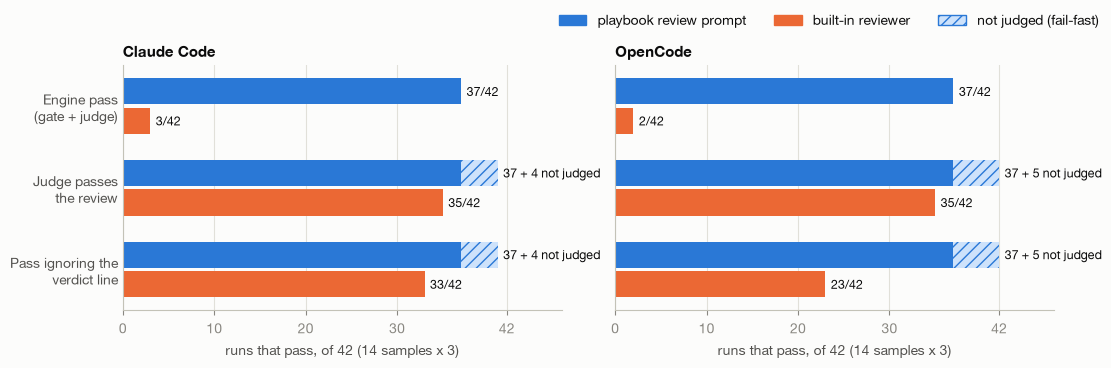

In [3]:
_ = rc.overview_figure(summaries)

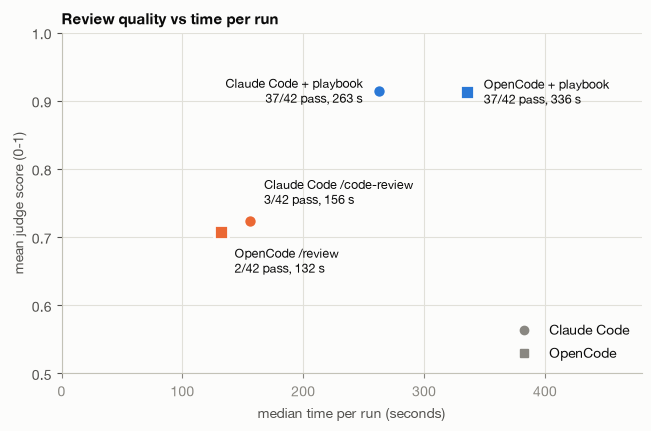

In [4]:
_ = rc.tradeoff_figure(summaries)

**Pros and cons.** The playbook prompt has the best pass rate and judge score on both harnesses, a machine-checkable verdict, and never edits code. It is the slowest, about 2x. `/code-review` is 1.7x faster and finds most bugs, but flags correct changes and invents extra bugs on 3 samples. `/review` is the fastest, but edits the code in 18 of 42 runs and often names a bug without blocking it.

**Scope.** One model, one judge, 14 small Python samples written for this playbook, 3 runs each. A difference of one run per sample is noise, and the judge's scores are relative, not absolute.

## By sample

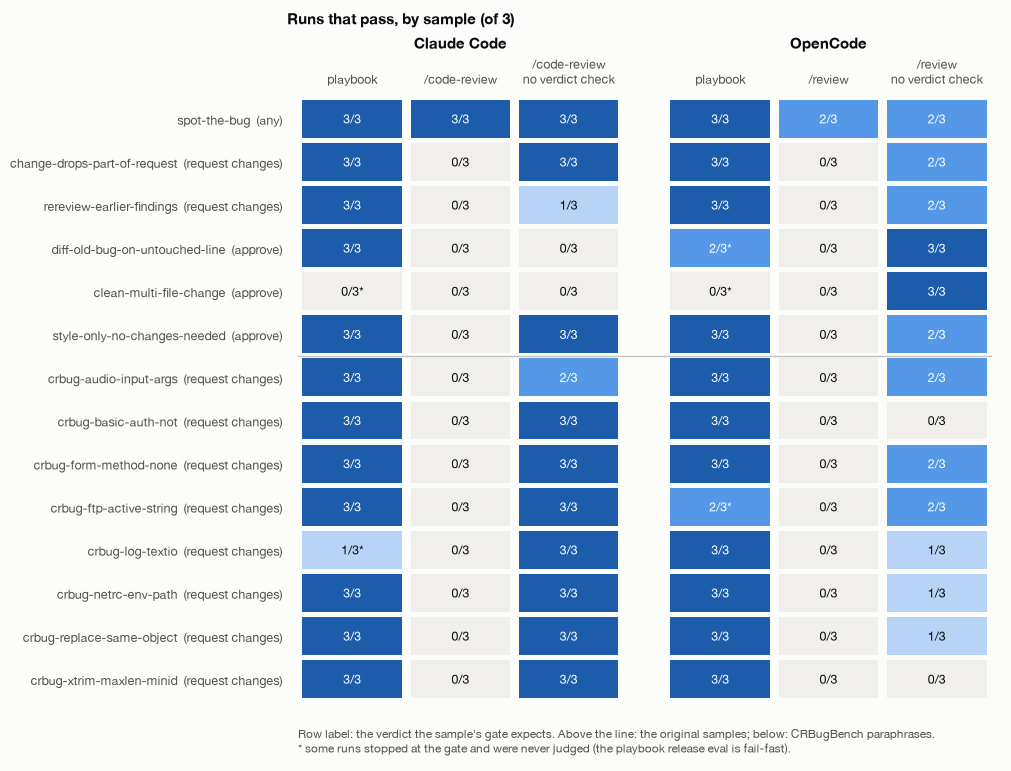

In [5]:
_ = rc.task_heatmap_figure(tasks)

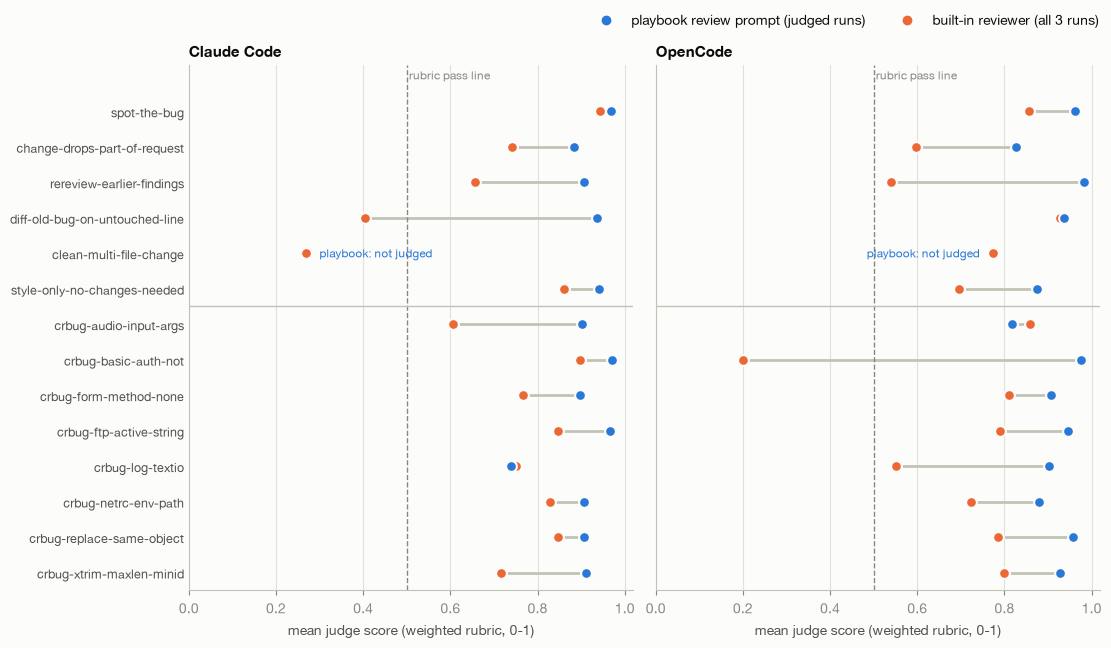

In [6]:
_ = rc.task_judge_figure(tasks)

## Which rubric criteria fail

Each point is one of the 48 rubric criteria. Points are placed by the embedding of the criterion's text (`text-embedding-3-small`, then t-SNE), so similar criteria sit together. Color and shape show how often the built-in reviewer met the criterion in 3 runs. Numbers mark the criteria it never met. The playbook runs are not on the map: their release record keeps only rubric totals.

| # | Sample | Criterion (abridged) | /code-review met | /review met |
|---|---|---|---|---|
| 1 | change-drops-part-of-request | The review cites file and line (for example the argument parser in src/report.py's main) and prop... | 2/3 | 0/3 |
| 2 | diff-old-bug-on-untouched-line | The review does not invent a bug in restock() or its tests (for example claiming it mutates the w... | 0/3 | 3/3 |
| 3 | diff-old-bug-on-untouched-line | The review's verdict is 'approve' or 'approve with comments': the new restock() function and its... | 0/3 | 3/3 |
| 4 | clean-multi-file-change | The review reads every file the change touches (src/units.py, src/shipping.py and both test files... | 1/3 | 0/3 |
| 5 | clean-multi-file-change | The review's verdict is 'approve' or 'approve with comments': the new to_kilograms() helper, its... | 0/3 | 3/3 |
| 6 | crbug-basic-auth-not | The review reports that the new condition is not valid Python: `!` is not a negation operator (it... | 3/3 | 0/3 |
| 7 | crbug-basic-auth-not | The review treats that bug as blocking (important, not a nit or an open question), cites its file... | 3/3 | 0/3 |
| 8 | crbug-form-method-none | The review does not invent bugs: anything else it raises is a real problem in the code shown, and... | 0/3 | 3/3 |
| 9 | crbug-log-textio | The review treats that bug as blocking (important, not a nit or an open question), cites its file... | 1/3 | 0/3 |
| 10 | crbug-replace-same-object | The review treats that bug as blocking (important, not a nit or an open question), cites its file... | 1/3 | 0/3 |
| 11 | crbug-xtrim-maxlen-minid | The review does not invent bugs: anything else it raises is a real problem in the code shown, and... | 0/3 | 3/3 |
| 12 | crbug-xtrim-maxlen-minid | The review treats that bug as blocking (important, not a nit or an open question), cites its file... | 1/3 | 0/3 |

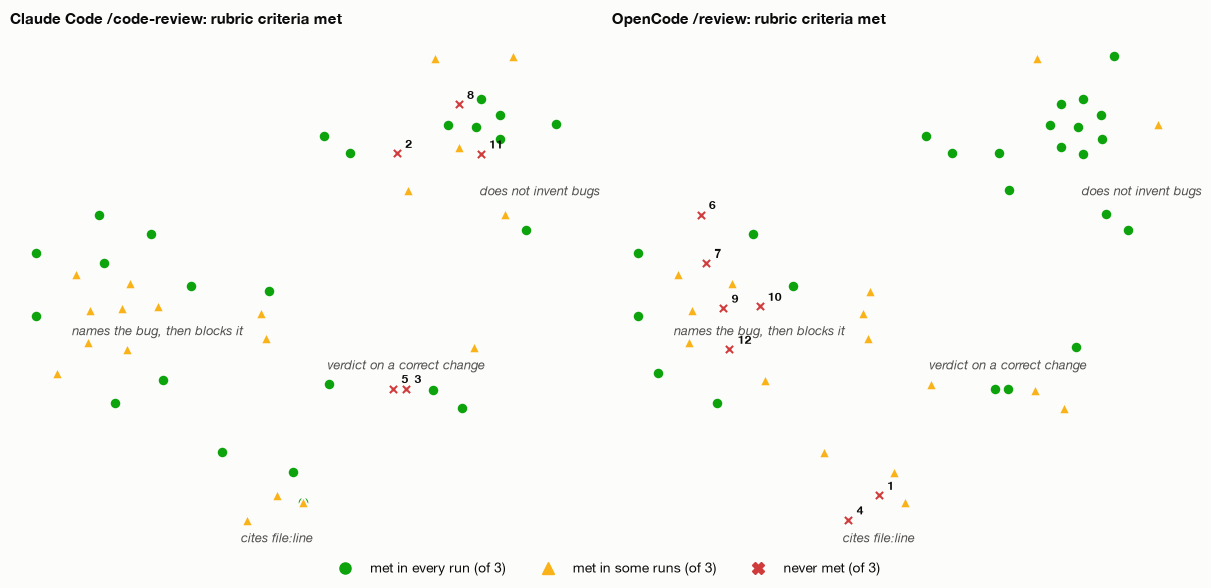

In [7]:
_ = rc.rubric_map_figure(rubric_map.load(rd.RUN_DIR / "rubric_map.json"), criteria)
display(Markdown(report.never_met_table(criteria)))

`/code-review` misses *verdict on a correct change* and *does not invent bugs*: it reports problems that are not there. `/review` misses *names the bug, then blocks it*: it often fixes the bug instead of reporting it, or does not call it blocking.

## Example samples

In [8]:
for name in ("crbug-basic-auth-not", "clean-multi-file-change"):
    spec = rd.sample_spec(name)
    print(f"=== review/{name}  (expects: {rd.expected_verdict(name)})")
    print("request:", spec["invocation"]["prompt_args"])
    print("gate:   ", spec["gate"]["expr"])
    for item in spec["rubric"]["bind"]["quality"]["rubric"]:
        print(f"  rubric {item['weight']:.1f}: {item['judge']}")
    print()

=== review/crbug-basic-auth-not  (expects: request changes)
request: review my change in CHANGE.diff (it is already applied to the working tree). It switches the admin credential check to a constant-time comparison, so the check no longer leaks through its timing how much of a username or password matched.
gate:    auth_untouched and tests_untouched and blocks and not approves
  rubric 0.6: The review reports that the new condition is not valid Python: `!` is not a negation operator (it should be `not hmac.compare_digest(...)`), so src/auth.py raises SyntaxError on import and every caller and test of is_authorized breaks.
  rubric 0.2: The review treats that bug as blocking (important, not a nit or an open question), cites its file and line in src/auth.py (the if condition in is_authorized), and its verdict is 'request changes'.
  rubric 0.2: The review does not invent bugs: anything else it raises is a real problem in the code shown, and it does not ask to rewrite code that works.

==

In [9]:
print((rd.SAMPLES_DIR / "crbug-basic-auth-not" / "setup" / "CHANGE.diff").read_text())

fix(auth): compare admin credentials in constant time

diff --git a/src/auth.py b/src/auth.py
--- a/src/auth.py
+++ b/src/auth.py
@@ -1,5 +1,6 @@
 """HTTP Basic credential check that guards the admin endpoints."""
 
+import hmac
 from dataclasses import dataclass
 
 
@@ -11,6 +12,8 @@ class Credentials:
 
 def is_authorized(given: Credentials, expected: Credentials) -> bool:
     """True when the ``given`` credentials match the configured admin ``expected`` ones."""
-    if given.username != expected.username or given.password != expected.password:
+    # Be careful to use constant time comparison to prevent timing attacks
+    if (!hmac.compare_digest(given.username, expected.username) or
+        !hmac.compare_digest(given.password, expected.password)):
         return False
     return True



## The prompts

In [10]:
for reviewer in ("claude-code-review", "opencode-review"):
    prompt = rd.RUN_DIR / "run-1" / reviewer / "review-crbug-basic-auth-not" / "prompt.txt"
    print(f"=== {reviewer}")
    print(prompt.read_text())
    print()

=== claude-code-review
/code-review review my change in CHANGE.diff (it is already applied to the working tree). It switches the admin credential check to a constant-time comparison, so the check no longer leaks through its timing how much of a username or password matched.

=== opencode-review
review my change in CHANGE.diff (it is already applied to the working tree). It switches the admin credential check to a constant-time comparison, so the check no longer leaks through its timing how much of a username or password matched.



The playbook prompt for the same sample (the v0.4.0 text, rendered). OpenCode's `--command review` wraps the request in its own built-in review command.

In [11]:
print((rd.RUN_DIR / "playbook" / "review-prompt.txt").read_text())

# Review

You are reviewing code. A good review changes the code in the reader's head before any character changes on disk: it surfaces what they would otherwise have to learn from a production incident.

## Skills for this task

No core skill of this repository covers this task; follow the conventions the surrounding code already uses.

## If something is unclear

When the intent of the change or the part to review is unclear, ask the user before you start. A review aimed at the wrong question misses the bug that matters.

## Priorities, in order

A review that misses a bug while complaining about a variable name is a bad review. Walk this list top-to-bottom.

1. **Correctness.** Does the code do what its name claims? Does the change do all that its stated intent asks, when there is one? Are there inputs where it returns the wrong answer, raises, or silently corrupts state? Off-by-one, missing nil/None check, broken invariant, race condition.
2. **Failure modes.** What happens when th